# Which penguin is it?

Machine learning from scratch, episode 3.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

df = fetch_openml("penguins", version=1, as_frame=True).frame
df.shape

(344, 7)

In [2]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
df.isna().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

In [4]:
df["sex"].value_counts(dropna=False)

sex
MALE      168
FEMALE    165
NaN        10
_           1
Name: count, dtype: int64

In [5]:
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [6]:
measures = ["culmen_length_mm", "culmen_depth_mm",
            "flipper_length_mm", "body_mass_g"]
df.groupby("species")[measures].mean().round(1)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


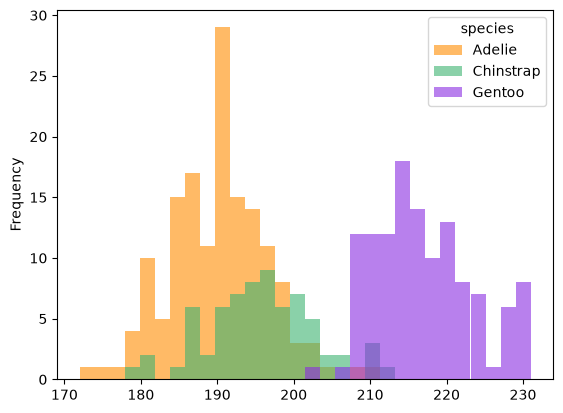

In [7]:
colors = {"Adelie": "darkorange", "Chinstrap": "mediumseagreen",
          "Gentoo": "blueviolet"}
flips = df.pivot(columns="species", values="flipper_length_mm")
flips.plot.hist(bins=30, alpha=0.6, color=colors);

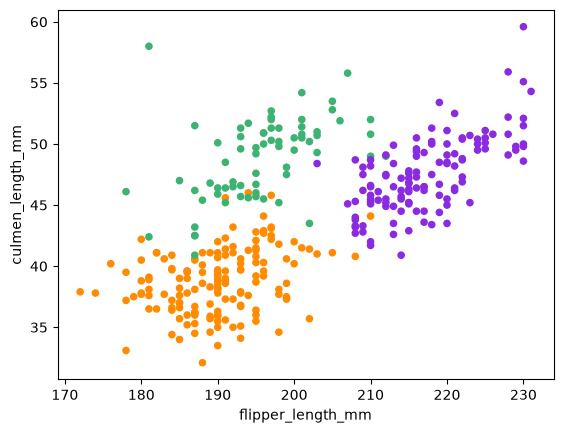

In [8]:
df.plot.scatter(x="flipper_length_mm", y="culmen_length_mm",
                c=df["species"].astype(str).map(colors));

In [9]:
pd.crosstab(df["island"], df["species"])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


In [10]:
df = df.dropna(subset=measures)
len(df)

342

In [11]:
X = df[measures]
y = df["species"]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
y_train.value_counts()

species
Adelie       113
Gentoo        92
Chinstrap     51
Name: count, dtype: int64

Gini impurity: $G = 1 - \sum_{k} p_k^2$

In [13]:
def gini(species):
    p = species.value_counts(normalize=True)
    return 1 - (p ** 2).sum()

print(round(gini(y_train), 3))

0.636


Entropy, in bits: $H = -\sum_{k} p_k \log_2 p_k$

In [14]:
import numpy as np

def entropy(species):
    p = species.value_counts(normalize=True)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

print(round(entropy(y_train), 3))

1.515


In [15]:
def after(feature, cut, measure):
    left = X_train[feature] <= cut
    share = left.mean()
    return (share * measure(y_train[left])
            + (1 - share) * measure(y_train[~left]))

print(round(after("flipper_length_mm", 206.5, gini), 3))

0.312


Information gain: $IG = H(\text{before}) - \sum_{i} \dfrac{n_i}{n} H(\text{group}_i)$

In [16]:
gain = entropy(y_train) - after("flipper_length_mm", 206.5, entropy)
print(round(gain, 3))

0.78


In [17]:
def best_cut(feature, measure):
    v = np.sort(X_train[feature].unique())
    cuts = (v[1:] + v[:-1]) / 2
    scores = [after(feature, c, measure) for c in cuts]
    i = np.argmin(scores)
    return len(cuts), float(cuts[i]), round(float(scores[i]), 3)

for feature in measures:
    print(feature, best_cut(feature, gini))

culmen_length_mm (144, 42.3, 0.324)
culmen_depth_mm (75, 16.4, 0.331)
flipper_length_mm (51, 206.5, 0.312)


body_mass_g (89, 4525.0, 0.4)


In [18]:
for feature in measures:
    print(feature, best_cut(feature, entropy))

culmen_length_mm (144, 42.3, 0.788)
culmen_depth_mm (75, 16.4, 0.778)


flipper_length_mm (51, 206.5, 0.735)
body_mass_g (89, 4175.0, 0.985)


In [19]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)
print(tree.get_depth(), tree.get_n_leaves())

7 14


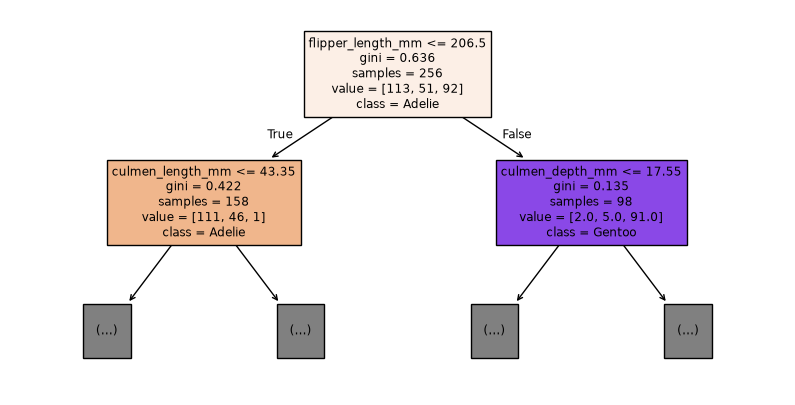

In [20]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(10, 5))
plot_tree(tree, max_depth=1, feature_names=measures,
          class_names=tree.classes_, filled=True);

In [21]:
tree.score(X_train, y_train)

1.0

In [22]:
from sklearn.model_selection import cross_val_score

for measure in ["gini", "entropy"]:
    t = DecisionTreeClassifier(criterion=measure, random_state=0)
    print(measure, cross_val_score(t, X_train, y_train).mean().round(3))

gini 0.965
entropy 0.973


Cost-complexity pruning: $R_\alpha(T) = R(T) + \alpha \, |T|$

In [23]:
deep = DecisionTreeClassifier(criterion="entropy", random_state=0)
path = deep.cost_complexity_pruning_path(X_train, y_train)
path.ccp_alphas.round(4)

array([0.    , 0.0078, 0.0105, 0.0159, 0.0162, 0.0236, 0.0487, 0.0821,
       0.1421, 0.3723, 0.7801])

In [24]:
for a in path.ccp_alphas[:-1]:
    t = DecisionTreeClassifier(criterion="entropy", ccp_alpha=a,
                               random_state=0)
    t.fit(X_train, y_train)
    score = cross_val_score(t, X_train, y_train).mean()
    print(round(a, 4), t.get_n_leaves(), round(score, 3))

0.0 12 0.973
0.0078 11 0.973
0.0105 10 0.973
0.0159 8 0.973
0.0162 7 0.965
0.0236 6 0.945
0.0487 5 0.93
0.0821 4 0.93
0.1421 3 0.922
0.3723 2 0.887


In [25]:
final = DecisionTreeClassifier(criterion="entropy", ccp_alpha=0.0159,
                               random_state=0)
final.fit(X_train, y_train)
print(final.get_n_leaves(), final.score(X_test, y_test))

8 0.9883720930232558


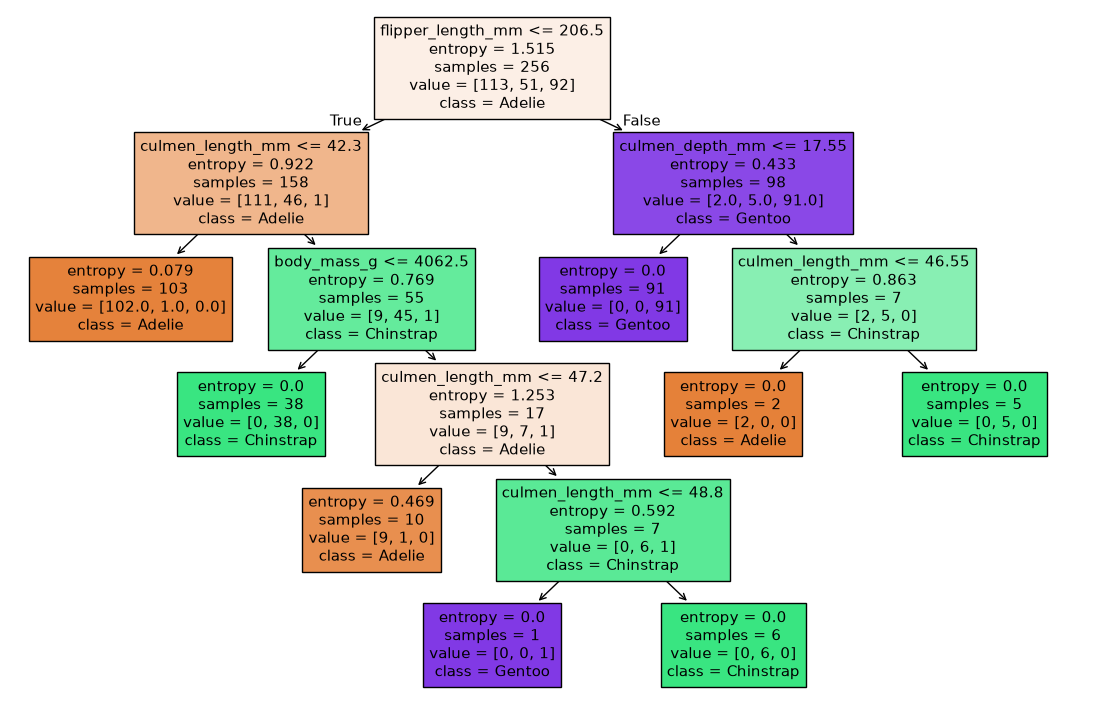

In [26]:
plt.figure(figsize=(14, 9))
plot_tree(final, feature_names=measures,
          class_names=final.classes_, filled=True);

In [27]:
pd.crosstab(y_test, final.predict(X_test), colnames=["guess"])

guess,Adelie,Chinstrap,Gentoo
species,,,
Adelie,37,1,0
Chinstrap,0,17,0
Gentoo,0,0,31


In [28]:
penguin = pd.DataFrame([[46.0, 18.5, 200.0, 4300.0]],
                       columns=measures)
print(final.predict(penguin))
pd.DataFrame(final.predict_proba(penguin),
             columns=final.classes_).round(2)

['Adelie']


,Adelie,Chinstrap,Gentoo
0,0.9,0.1,0.0
